# Taller 1: CAPM en dos mercados

**Julián Duarte -- Valoración de Activos (DEFI 2)**

Este notebook reconstruye la base del expediente, audita datos, estima CAPM con errores HAC, calcula métricas de riesgo/liquidez/robustez, produce las siete visualizaciones obligatorias y cierra con la recomendación técnica para Doña Victoria.

In [1]:
import sys, subprocess, importlib, os
from pathlib import Path

base_dir = Path.cwd()
for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
    if (p / '01_datos').exists():
        base_dir = p
        break
datos_dir = base_dir / '01_datos'
graficos_dir = base_dir / '04_graficos'
scripts_dir = base_dir / '05_scripts'

print('Python:', sys.version)
for pkg in ['numpy','pandas','matplotlib','seaborn','statsmodels','yfinance','nbformat']:
    mod = importlib.import_module(pkg)
    print(pkg, getattr(mod, '__version__', 'ok'))

print('Entorno y versiones registrados.')

Python: 3.12.3 (main, Jun 19 2026, 12:46:00) [GCC 13.3.0]
numpy 2.4.3


pandas 3.0.1
matplotlib 3.10.8


seaborn 0.13.2
statsmodels 0.15.0


yfinance 1.7.0


nbformat 5.10.4
Entorno y versiones registrados.


In [2]:
# Ejecuta el pipeline reproducible: descarga precios/volumen, alinea calendarios,
# construye retornos/excesos, estima metricas y regenera tablas/graficos.
script_target = str(scripts_dir / 'rebuild_entregables.py')
exec(open(script_target).read())

Entregables reconstruidos exitosamente.
Filas dataset: 499 Columnas: 88
Ticker Benchmark     Beta       R2       MDD  Pct_Zero_Returns
   SOL       NCI 1.252911 0.664097 -0.754464          0.000000
  KOPN       XLK 1.822791 0.228278 -0.635468          3.607214
  MVIS       XLK 1.156314 0.089643 -0.939194         11.022044
  LIDR       XLK 1.271184 0.043027 -0.829766          3.807615
  GERN       XBI 1.124856 0.218226 -0.774737          8.016032
  CTMX       XBI 1.518318 0.106913 -0.670229          3.206413
  OCGN       XBI 1.150639 0.166948 -0.612030          5.811623
  BORR       XLE 1.356812 0.265980 -0.747817          4.408818
  KLXE       XLE 1.938363 0.203017 -0.798928          3.406814
   TTI       XLE 1.135007 0.183221 -0.572289          2.004008


In [3]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(datos_dir / 'datos_taller_1_julian_duarte.csv', parse_dates=['Date'])
master = pd.read_csv(datos_dir / 'tabla_maestra_resultados.csv')
seleccion = pd.read_csv(datos_dir / 'evidencia_seleccion_activos.csv')

print(df.shape, df['Date'].min(), df['Date'].max())
display(seleccion)
display(master[['Ticker','Benchmark','Beta','CI_Beta_Low','CI_Beta_High','R2','Observed_Return','CAPM_Expected_Return']])

(499, 88) 2024-08-27 00:00:00 2026-08-24 00:00:00


,Ticker,Empresa,Sector declarado,Benchmark,Precio seleccion USD,Fecha consulta,Mercado/Fuente,Clasificacion,Cumple precio
0,SOL,Solana,Criptoactivos,NCI,87.6369,2026-08-20,Yahoo Finance; NCI.csv suministrado por profes...,Criptoactivo asignado,No aplica
1,KOPN,Kopin Corporation,Tecnologia,XLK,4.8900,2026-08-20,Yahoo Finance; NCI.csv suministrado por profes...,Penny stock,Si
2,MVIS,"MicroVision, Inc.",Tecnologia,XLK,1.7500,2026-08-20,Yahoo Finance; NCI.csv suministrado por profes...,Penny stock,Si
3,LIDR,"AEye, Inc.",Tecnologia,XLK,1.2600,2026-08-20,Yahoo Finance; NCI.csv suministrado por profes...,Penny stock,Si
4,GERN,Geron Corporation,Biotecnologia,XBI,1.5500,2026-08-20,Yahoo Finance; NCI.csv suministrado por profes...,Penny stock,Si
5,CTMX,"CytomX Therapeutics, Inc.",Biotecnologia,XBI,3.2900,2026-08-20,Yahoo Finance; NCI.csv suministrado por profes...,Penny stock,Si
6,OCGN,"Ocugen, Inc.",Biotecnologia,XBI,1.3900,2026-08-20,Yahoo Finance; NCI.csv suministrado por profes...,Penny stock,Si
7,BORR,Borr Drilling Limited,Energia,XLE,4.4300,2026-08-20,Yahoo Finance; NCI.csv suministrado por profes...,Penny stock,Si
8,KLXE,"KLX Energy Services Holdings, Inc.",Energia,XLE,1.6300,2026-08-20,Yahoo Finance; NCI.csv suministrado por profes...,Penny stock,Si
9,TTI,"TETRA Technologies, Inc.",Energia,XLE,7.2300,2026-08-20,Yahoo Finance; NCI.csv suministrado por profes...,Accion de bajo precio (excepcion < USD 10),Excepcion < USD 10


,Ticker,Benchmark,Beta,CI_Beta_Low,CI_Beta_High,R2,Observed_Return,CAPM_Expected_Return
0,SOL,NCI,1.252911,1.163170,1.342651,0.664097,0.046244,0.334829
1,KOPN,XLK,1.822791,1.573883,2.071698,0.228278,1.299632,0.493080
2,MVIS,XLK,1.156314,0.841393,1.471235,0.089643,-0.501440,0.327633
3,LIDR,XLK,1.271184,0.960186,1.582183,0.043027,0.957423,0.356149
4,GERN,XBI,1.124856,0.976742,1.272971,0.218226,-0.328693,0.312737
5,CTMX,XBI,1.518318,0.901690,2.134947,0.106913,1.135384,0.407930
6,OCGN,XBI,1.150639,0.963244,1.338035,0.166948,0.295982,0.318974
7,BORR,XLE,1.356812,1.111022,1.602603,0.265980,-0.006248,0.289120
8,KLXE,XLE,1.938363,1.591616,2.285110,0.203017,-0.282013,0.395644
9,TTI,XLE,1.135007,0.866376,1.403639,0.183221,0.546796,0.248492


In [4]:
activos = ['SOL','KOPN','MVIS','LIDR','GERN','CTMX','OCGN','BORR','KLXE','TTI']
auditoria = []
for t in activos:
    r = df[f'{t}_Return']
    auditoria.append({
        'Activo': t,
        'Inicio': df['Date'].min().date(),
        'Fin': df['Date'].max().date(),
        'Obs': len(r),
        'Faltantes': int(r.isna().sum()),
        'Duplicados fecha': int(df['Date'].duplicated().sum()),
        'Retornos cero (%)': round((r == 0).mean()*100, 2),
        'Volumen mediano': round(df[f'{t}_Volume'].median(), 0),
        '5 peores retornos': ', '.join(f'{x:.2%}' for x in r.nsmallest(5)),
        '5 mejores retornos': ', '.join(f'{x:.2%}' for x in r.nlargest(5)),
    })
display(pd.DataFrame(auditoria))

,Activo,Inicio,Fin,Obs,Faltantes,Duplicados fecha,Retornos cero (%),Volumen mediano,5 peores retornos,5 mejores retornos
0,SOL,2024-08-27,2026-08-24,499,0,0,0.00,4.498613e+09,"-15.93%, -15.43%, -15.04%, -15.03%, -14.63%","14.02%, 12.84%, 12.14%, 11.87%, 11.38%"
1,KOPN,2024-08-27,2026-08-24,499,0,0,3.61,2.716300e+06,"-36.46%, -25.20%, -16.09%, -14.55%, -13.54%","26.60%, 26.53%, 23.52%, 22.97%, 20.55%"
2,MVIS,2024-08-27,2026-08-24,499,0,0,11.02,2.917130e+05,"-40.58%, -31.67%, -29.49%, -21.05%, -20.12%","31.58%, 27.75%, 27.27%, 25.23%, 18.03%"
3,LIDR,2024-08-27,2026-08-24,499,0,0,3.81,8.129000e+05,"-32.64%, -27.09%, -24.85%, -20.22%, -17.16%","158.41%, 59.38%, 51.88%, 39.37%, 38.50%"
4,GERN,2024-08-27,2026-08-24,499,0,0,8.02,9.923000e+06,"-32.07%, -11.79%, -9.22%, -9.13%, -9.09%","21.64%, 15.83%, 12.41%, 11.41%, 10.62%"
5,CTMX,2024-08-27,2026-08-24,499,0,0,3.21,2.030800e+06,"-19.48%, -19.27%, -19.26%, -16.02%, -15.97%","129.53%, 44.23%, 26.82%, 19.83%, 17.84%"
6,OCGN,2024-08-27,2026-08-24,499,0,0,5.81,4.141800e+06,"-19.46%, -13.83%, -11.75%, -11.22%, -10.78%","29.94%, 19.42%, 19.04%, 18.67%, 13.59%"
7,BORR,2024-08-27,2026-08-24,499,0,0,4.41,4.798700e+06,"-15.28%, -11.86%, -10.91%, -9.63%, -9.01%","19.57%, 13.02%, 10.13%, 9.68%, 9.65%"
8,KLXE,2024-08-27,2026-08-24,499,0,0,3.41,1.518000e+05,"-30.80%, -25.97%, -18.89%, -17.17%, -15.44%","28.18%, 22.89%, 20.38%, 20.23%, 19.80%"
9,TTI,2024-08-27,2026-08-24,499,0,0,2.00,1.408300e+06,"-18.67%, -17.22%, -12.72%, -10.56%, -9.75%","22.71%, 18.93%, 13.55%, 11.15%, 10.91%"


In [5]:
print('Tabla maestra 1: CAPM')
display(master[['Ticker','Family','Benchmark','Alpha_Annual','Beta','SE_Beta','CI_Beta_Low','CI_Beta_High','P_Val_Beta','P_Val_Alpha','R2','R2_Adj','Observed_Return','CAPM_Expected_Return']])

print('Tabla maestra 2: riesgo, desempeno y liquidez')
display(master[['Ticker','Vol_Annual','Sharpe','Treynor','Sortino','MDD','VaR_95_Daily','CVaR_95_Daily','Best_Day','Worst_Day','Skewness','Kurtosis','Pct_Zero_Returns','Med_Volume','Med_Monetary_Volume','Amihud_Illiquidity','Beta_Minus','Beta_Dimson_Sum','Beta_Winsor','T_Beta_1']])

Tabla maestra 1: CAPM


,Ticker,Family,Benchmark,Alpha_Annual,Beta,SE_Beta,CI_Beta_Low,CI_Beta_High,P_Val_Beta,P_Val_Alpha,R2,R2_Adj,Observed_Return,CAPM_Expected_Return
0,SOL,Cripto,NCI,-0.288585,1.252911,0.045787,1.163170,1.342651,7.376926e-165,0.456069,0.664097,0.663421,0.046244,0.334829
1,KOPN,Tecnologia,XLK,0.806553,1.822791,0.126996,1.573883,2.071698,1.018332e-46,0.187240,0.228278,0.226725,1.299632,0.493080
2,MVIS,Tecnologia,XLK,-0.829073,1.156314,0.160677,0.841393,1.471235,6.176910e-13,0.213949,0.089643,0.087811,-0.501440,0.327633
3,LIDR,Tecnologia,XLK,0.601274,1.271184,0.158676,0.960186,1.582183,1.135830e-15,0.615904,0.043027,0.041101,0.957423,0.356149
4,GERN,Biotecnologia,XBI,-0.641430,1.124856,0.075570,0.976742,1.272971,4.125521e-50,0.077574,0.218226,0.216653,-0.328693,0.312737
5,CTMX,Biotecnologia,XBI,0.727454,1.518318,0.314612,0.901690,2.134947,1.393039e-06,0.370818,0.106913,0.105116,1.135384,0.407930
6,OCGN,Biotecnologia,XBI,-0.022993,1.150639,0.095612,0.963244,1.338035,2.340700e-33,0.963730,0.166948,0.165272,0.295982,0.318974
7,BORR,Energia,XLE,-0.295368,1.356812,0.125406,1.111022,1.602603,2.786686e-27,0.433131,0.265980,0.264503,-0.006248,0.289120
8,KLXE,Energia,XLE,-0.677657,1.938363,0.176915,1.591616,2.285110,6.186803e-28,0.253271,0.203017,0.201413,-0.282013,0.395644
9,TTI,Energia,XLE,0.298305,1.135007,0.137059,0.866376,1.403639,1.219997e-16,0.476440,0.183221,0.181578,0.546796,0.248492


Tabla maestra 2: riesgo, desempeno y liquidez


,Ticker,Vol_Annual,Sharpe,Treynor,Sortino,MDD,VaR_95_Daily,CVaR_95_Daily,Best_Day,Worst_Day,Skewness,Kurtosis,Pct_Zero_Returns,Med_Volume,Med_Monetary_Volume,Amihud_Illiquidity,Beta_Minus,Beta_Dimson_Sum,Beta_Winsor,T_Beta_1
0,SOL,0.879989,0.006426,0.004514,0.006700,-0.754464,-0.070040,-0.099922,0.140206,-0.159286,0.007003,0.953539,0.000000,4.498613e+09,5.984322e+11,6.193357e-14,1.236691,1.309523,1.312931,5.523638
1,KOPN,1.032813,1.219042,0.690722,1.336825,-0.635468,-0.083819,-0.123515,0.265957,-0.364583,0.189241,3.380916,3.607214,2.716300e+06,5.170987e+06,1.455354e-08,2.212307,1.670172,1.886023,6.478870
2,MVIS,1.045543,-0.518419,-0.468757,-0.490599,-0.939194,-0.093023,-0.151422,0.315789,-0.405836,-0.233513,6.596688,11.022044,2.917130e+05,3.850092e+06,1.077381e-08,1.116516,1.054193,1.292553,0.972847
3,LIDR,1.659052,0.552625,0.721243,0.904609,-0.829766,-0.088653,-0.140857,1.584071,-0.326425,7.736692,108.205409,3.807615,8.129000e+05,1.187231e+06,9.543895e-08,1.308117,1.443874,1.377016,1.709047
4,GERN,0.665522,-0.554877,-0.328294,-0.552033,-0.774737,-0.062599,-0.086893,0.216418,-0.320675,-0.288864,7.980809,8.016032,9.923000e+06,1.771708e+07,1.813177e-09,1.180649,1.358085,1.166723,1.652198
5,CTMX,1.283431,0.853021,0.721057,1.415842,-0.670229,-0.076097,-0.114910,1.295259,-0.194805,8.577018,131.868958,3.206413,2.030800e+06,6.005472e+06,1.968095e-08,1.261889,1.072451,1.260598,1.647483
6,OCGN,0.778339,0.328124,0.221957,0.366711,-0.612030,-0.070459,-0.091820,0.299435,-0.194595,0.816894,3.863131,5.811623,4.141800e+06,4.479557e+06,7.897832e-09,1.406440,0.939756,1.183986,1.575532
7,BORR,0.617178,-0.075890,-0.034520,-0.077272,-0.747817,-0.060623,-0.080018,0.195652,-0.152838,0.254830,1.586392,4.408818,4.798700e+06,1.595695e+07,1.945703e-09,1.299525,1.264294,1.306565,2.845262
8,KLXE,1.009237,-0.319650,-0.166430,-0.346841,-0.798928,-0.085695,-0.129506,0.281818,-0.308036,0.358604,2.911857,3.406814,1.518000e+05,4.533780e+05,1.061972e-07,2.095204,1.917243,2.050517,5.304035
9,TTI,0.622070,0.813745,0.445994,0.828606,-0.572289,-0.058425,-0.083965,0.227119,-0.186715,0.189390,4.673530,2.004008,1.408300e+06,8.100123e+06,4.325729e-09,1.302511,1.140787,1.129516,0.985029


## Visualizaciones obligatorias

A continuación se presentan las siete visualizaciones obligatorias del análisis econométrico y financiero:

1. Precios normalizados a base 100 por expediente.
2. Dispersión CAPM con recta de regresión e intervalo de confianza.
3. Forest plot de betas con intervalos de confianza HAC Newey-West.
4. Beta móvil de 90 observaciones para la estabilidad temporal.
5. Mapa riesgo-retorno (Volatilidad vs Retorno observados).
6. Drawdown acumulado y profundidad de caídas.
7. Matriz final de percentiles por familia de activos.

=== Visualizacion: grafico_1_precios_normalizados.png ===


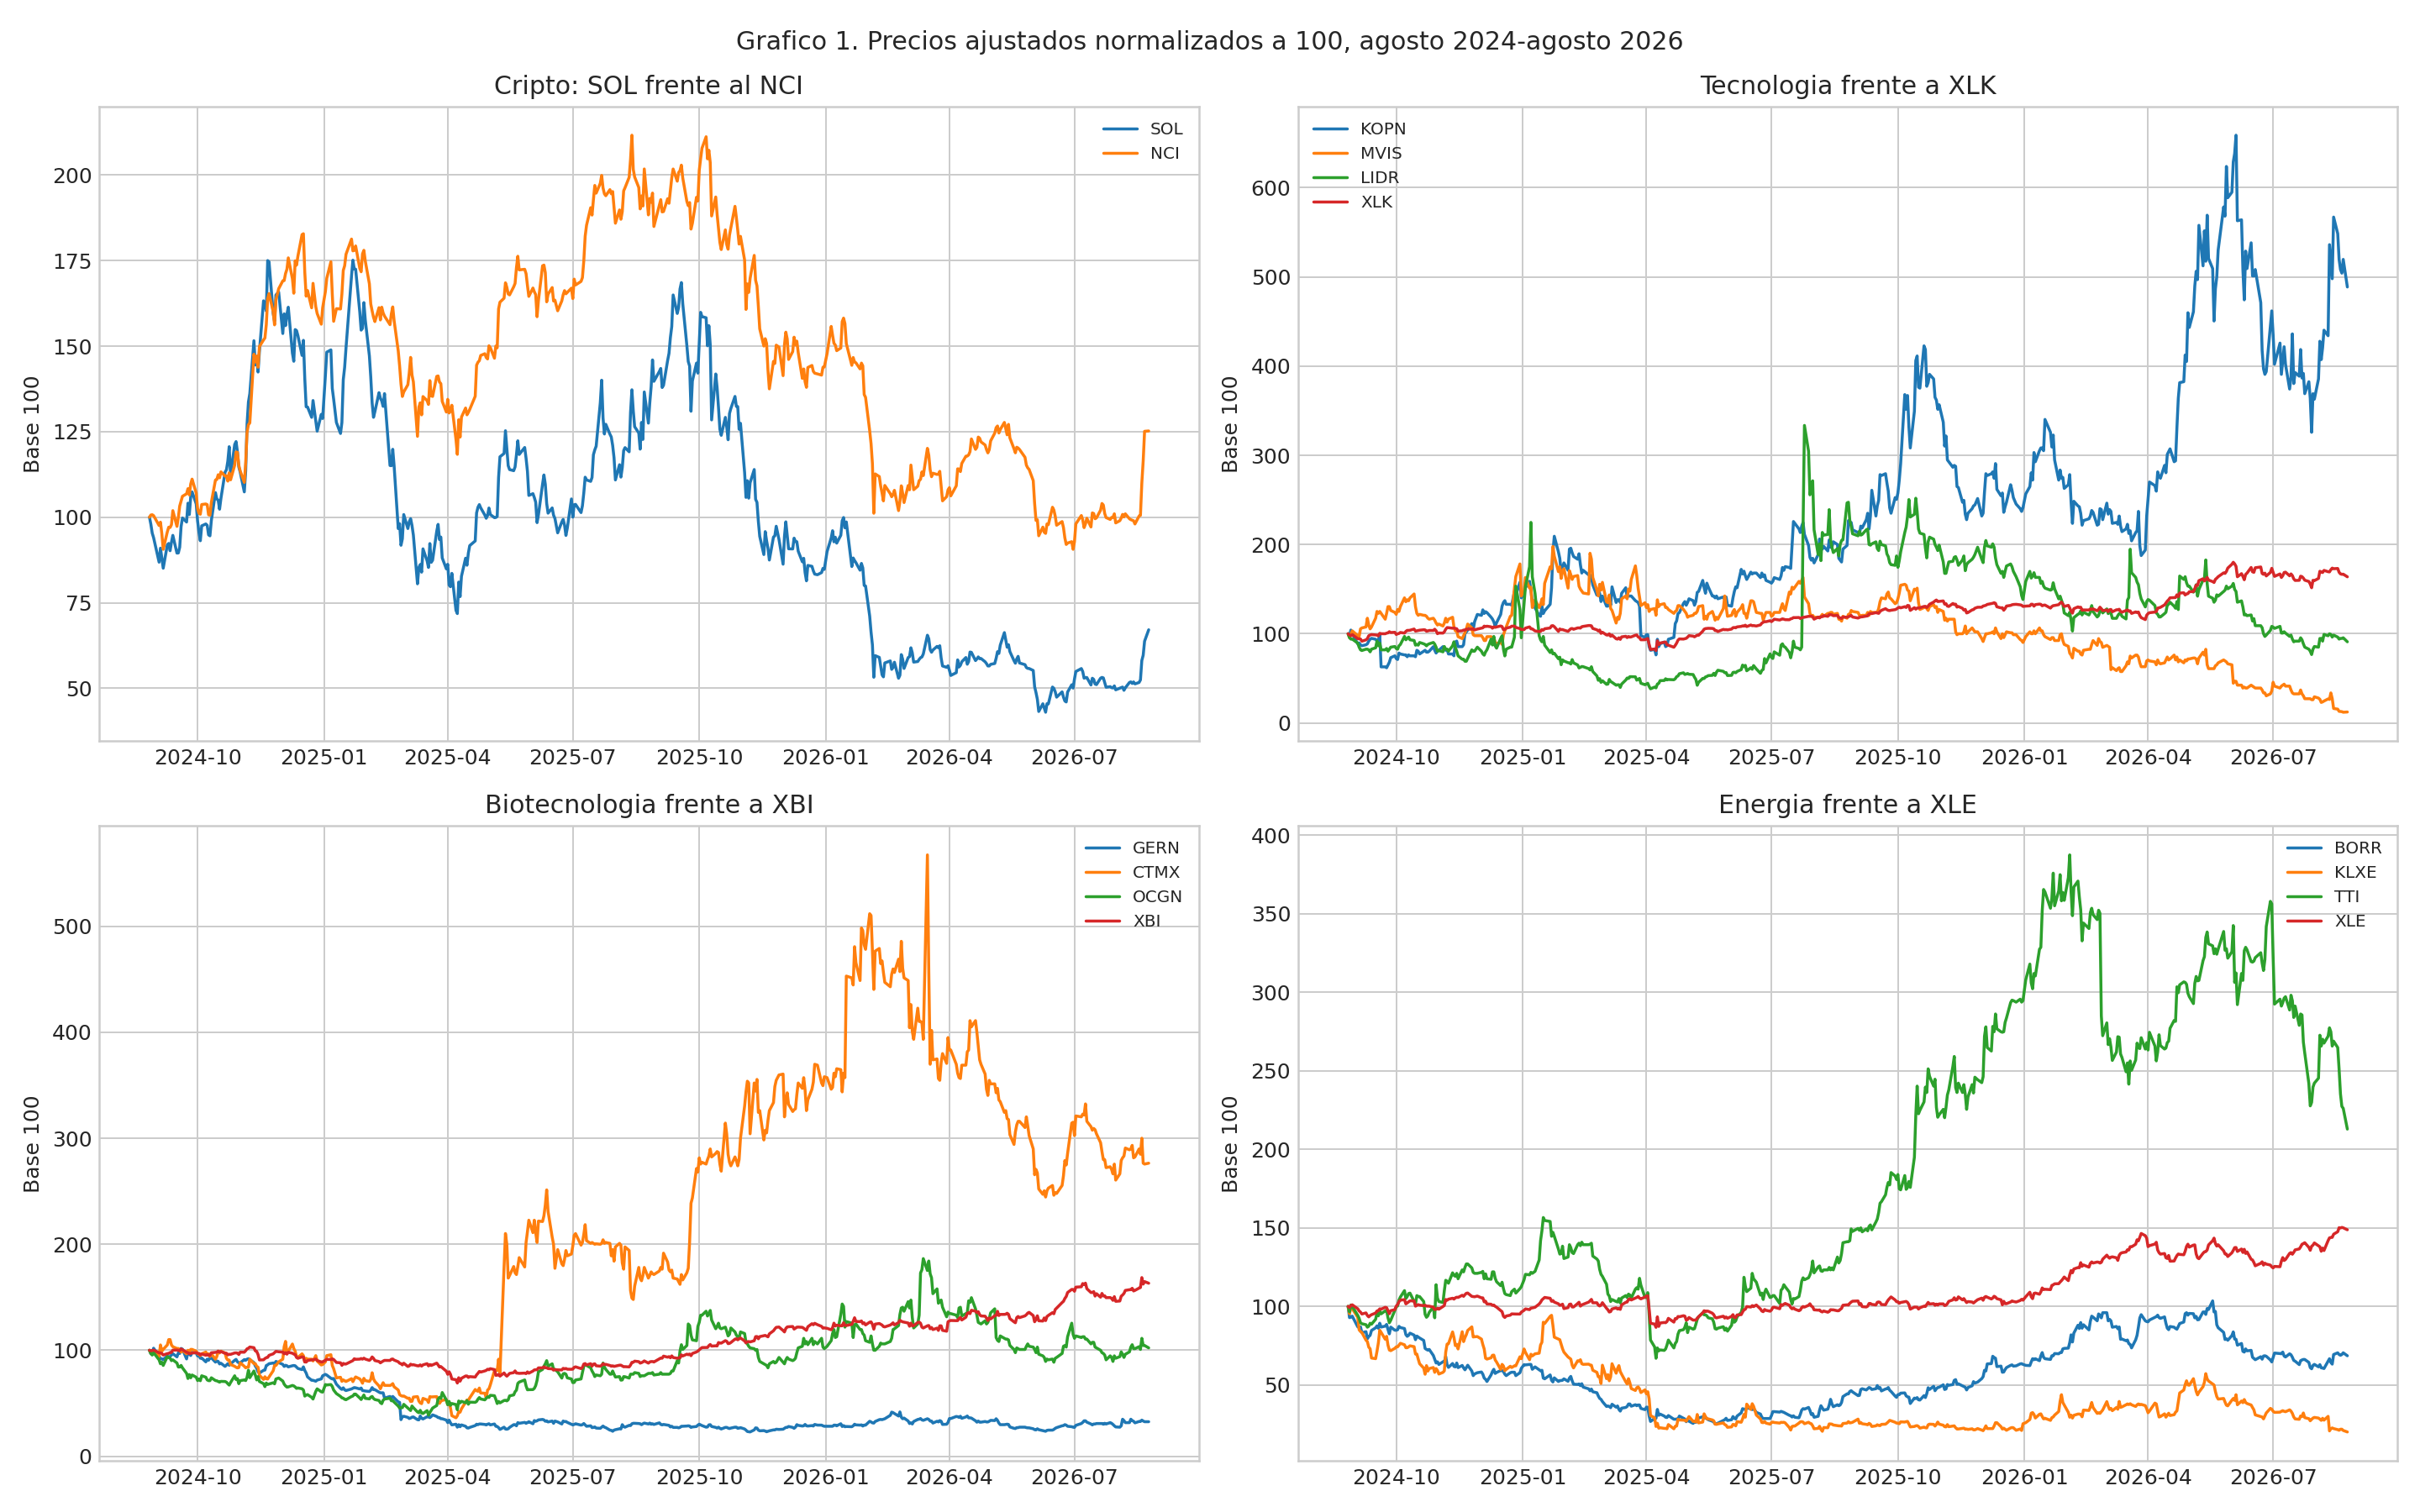

=== Visualizacion: grafico_2_recta_capm_todos.png ===


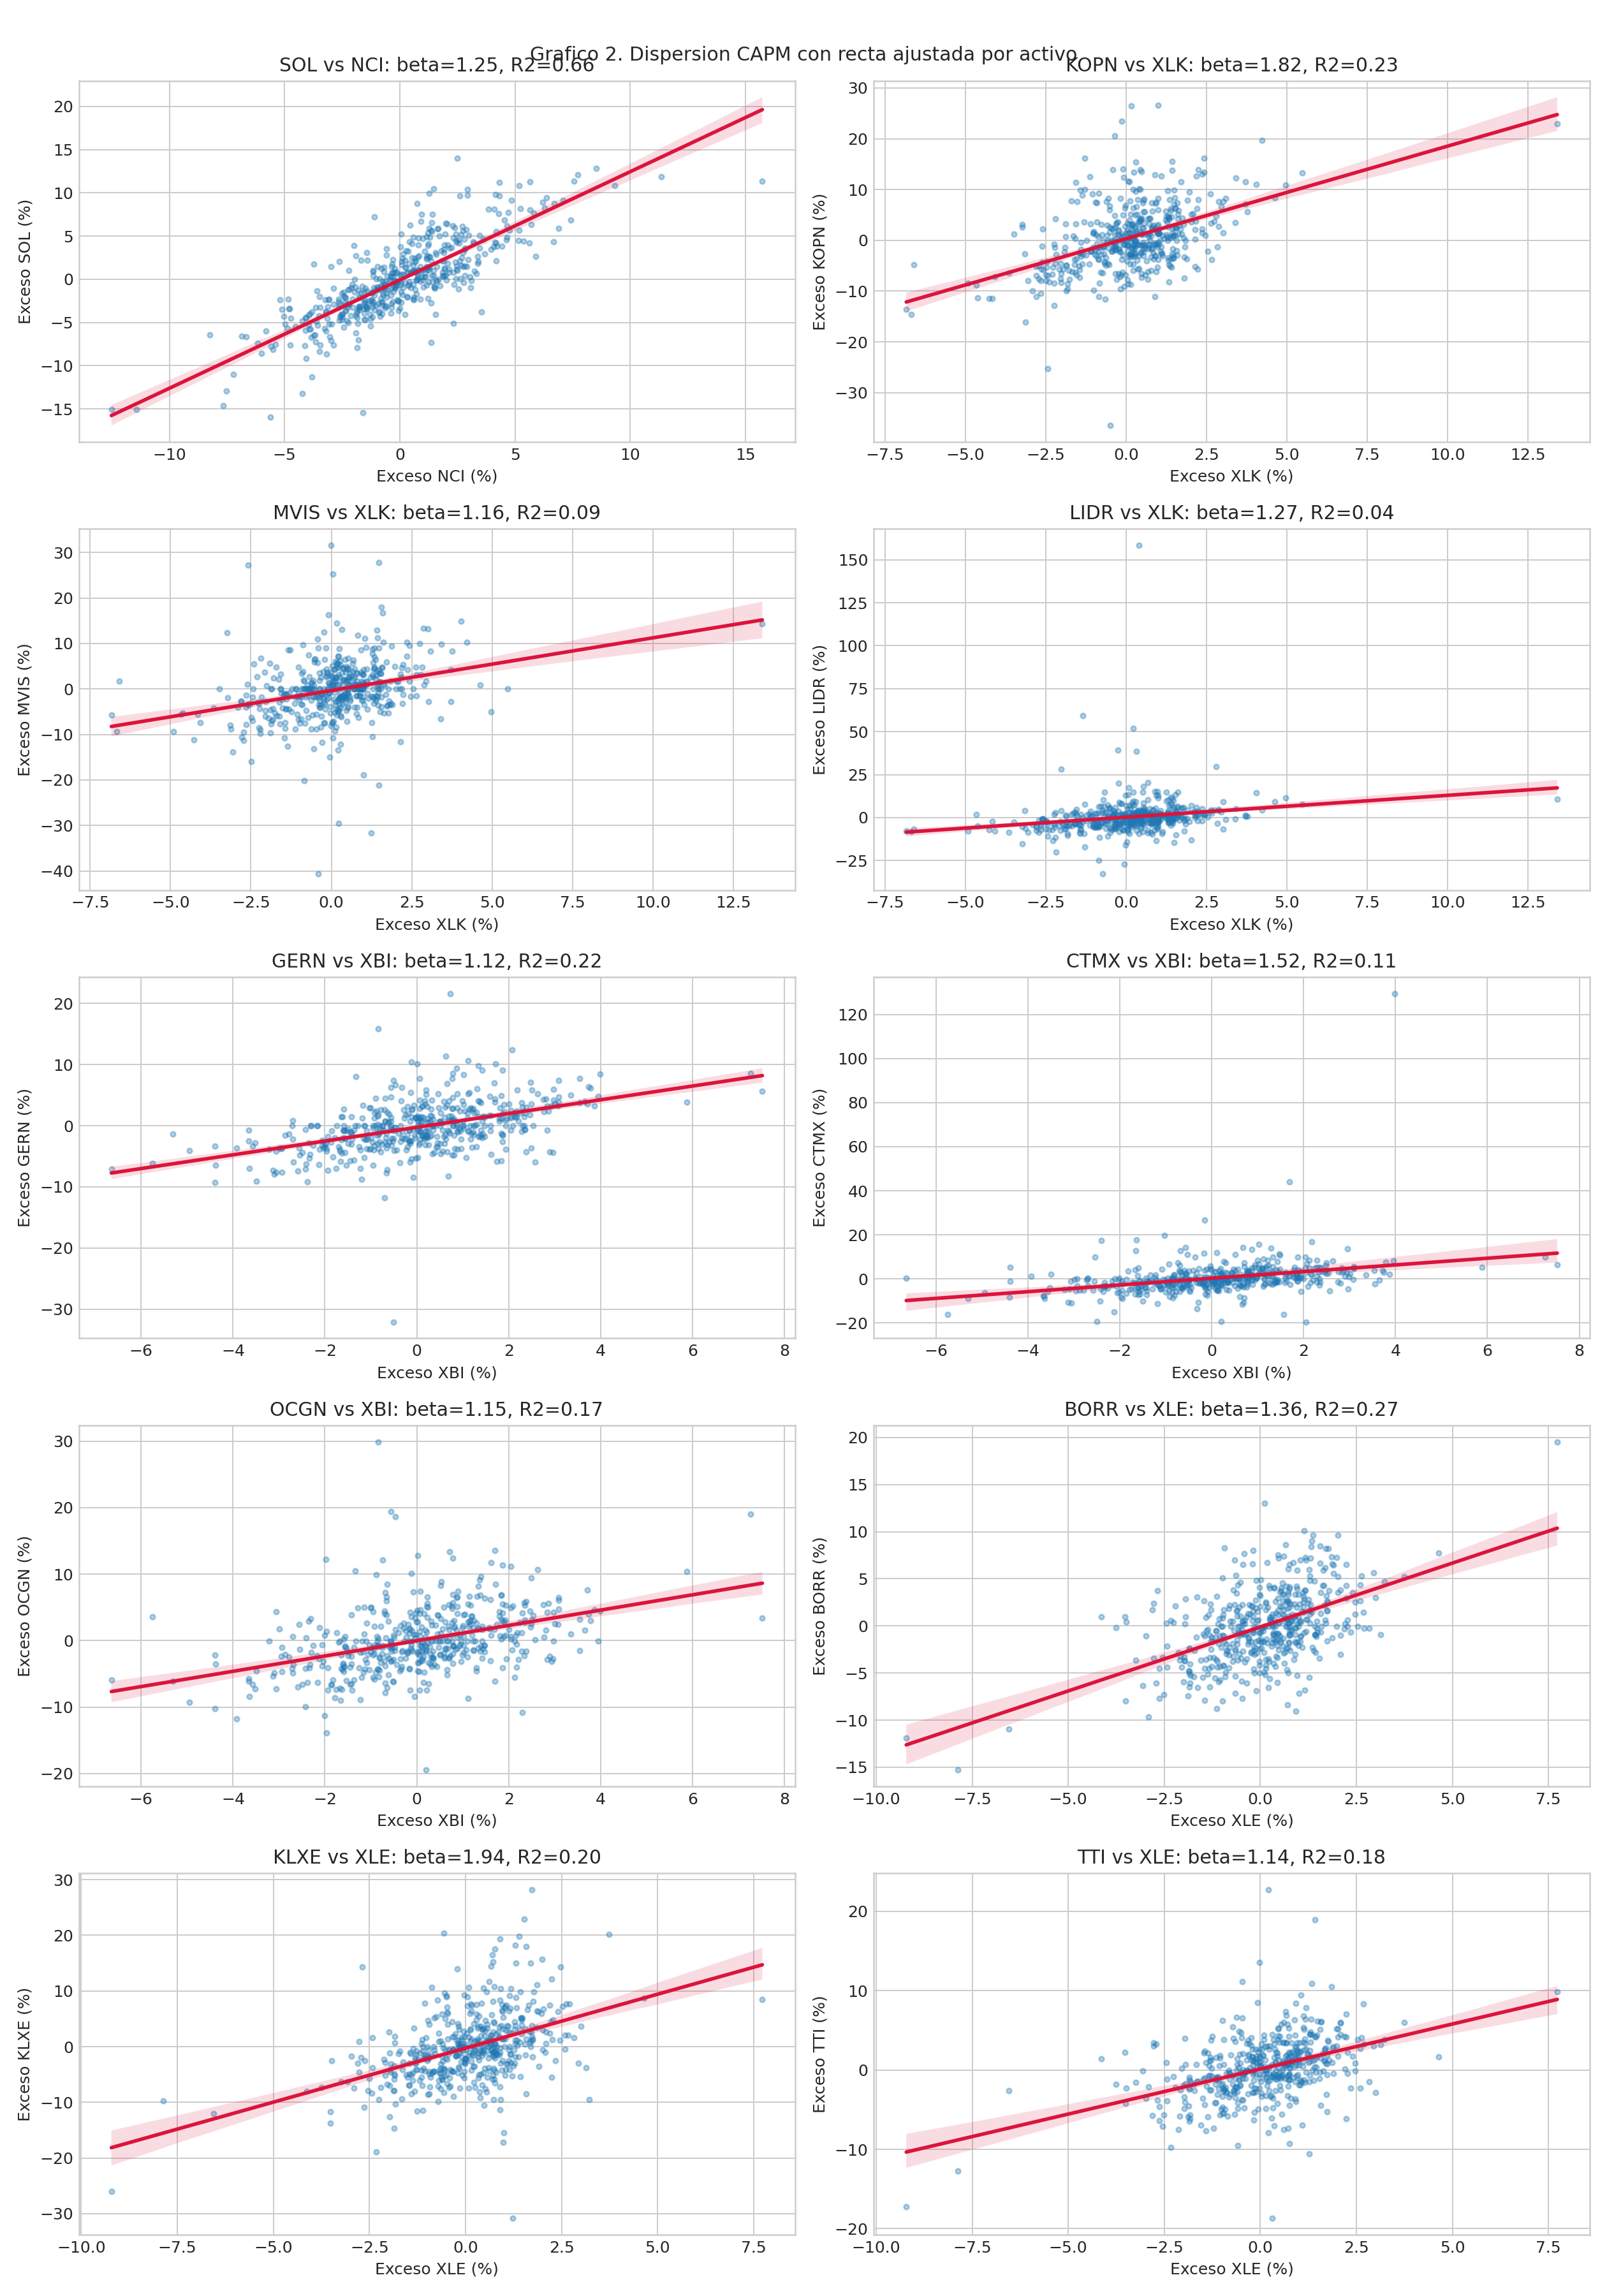

=== Visualizacion: grafico_3_forest_plot_betas.png ===


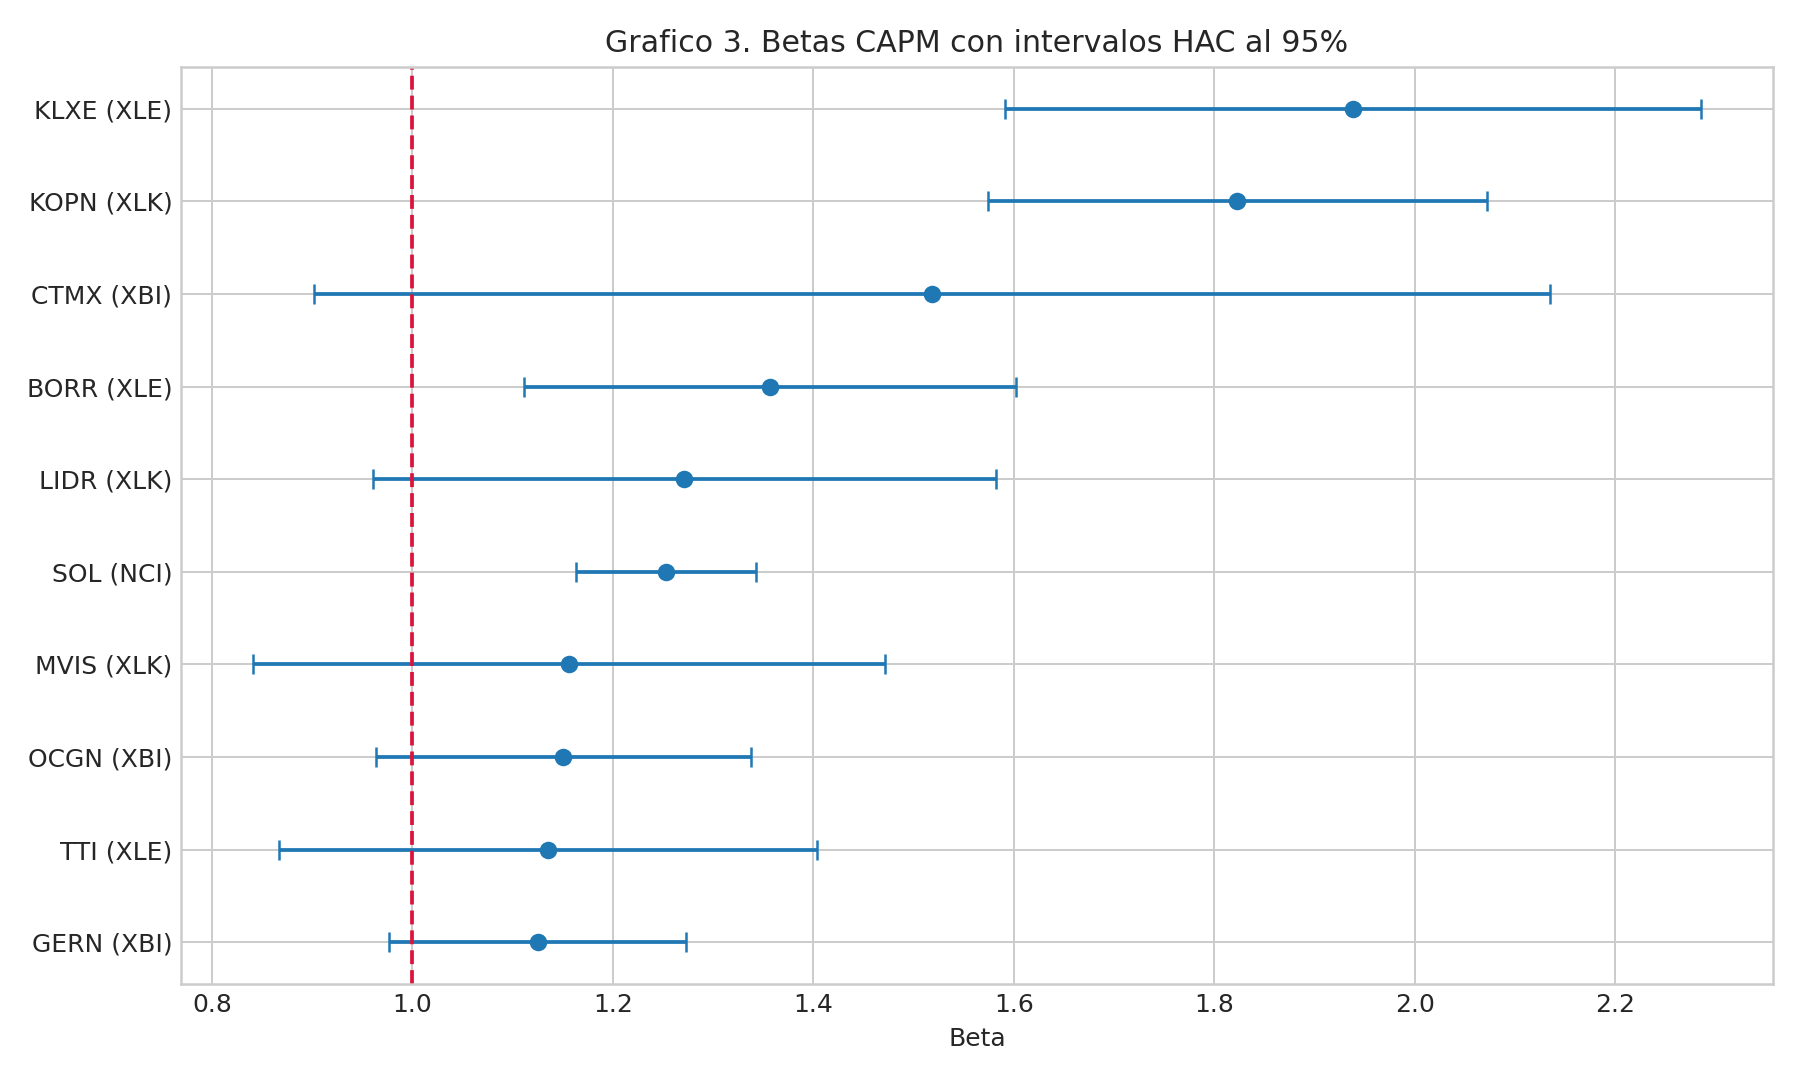

=== Visualizacion: grafico_4_beta_movil_todos.png ===


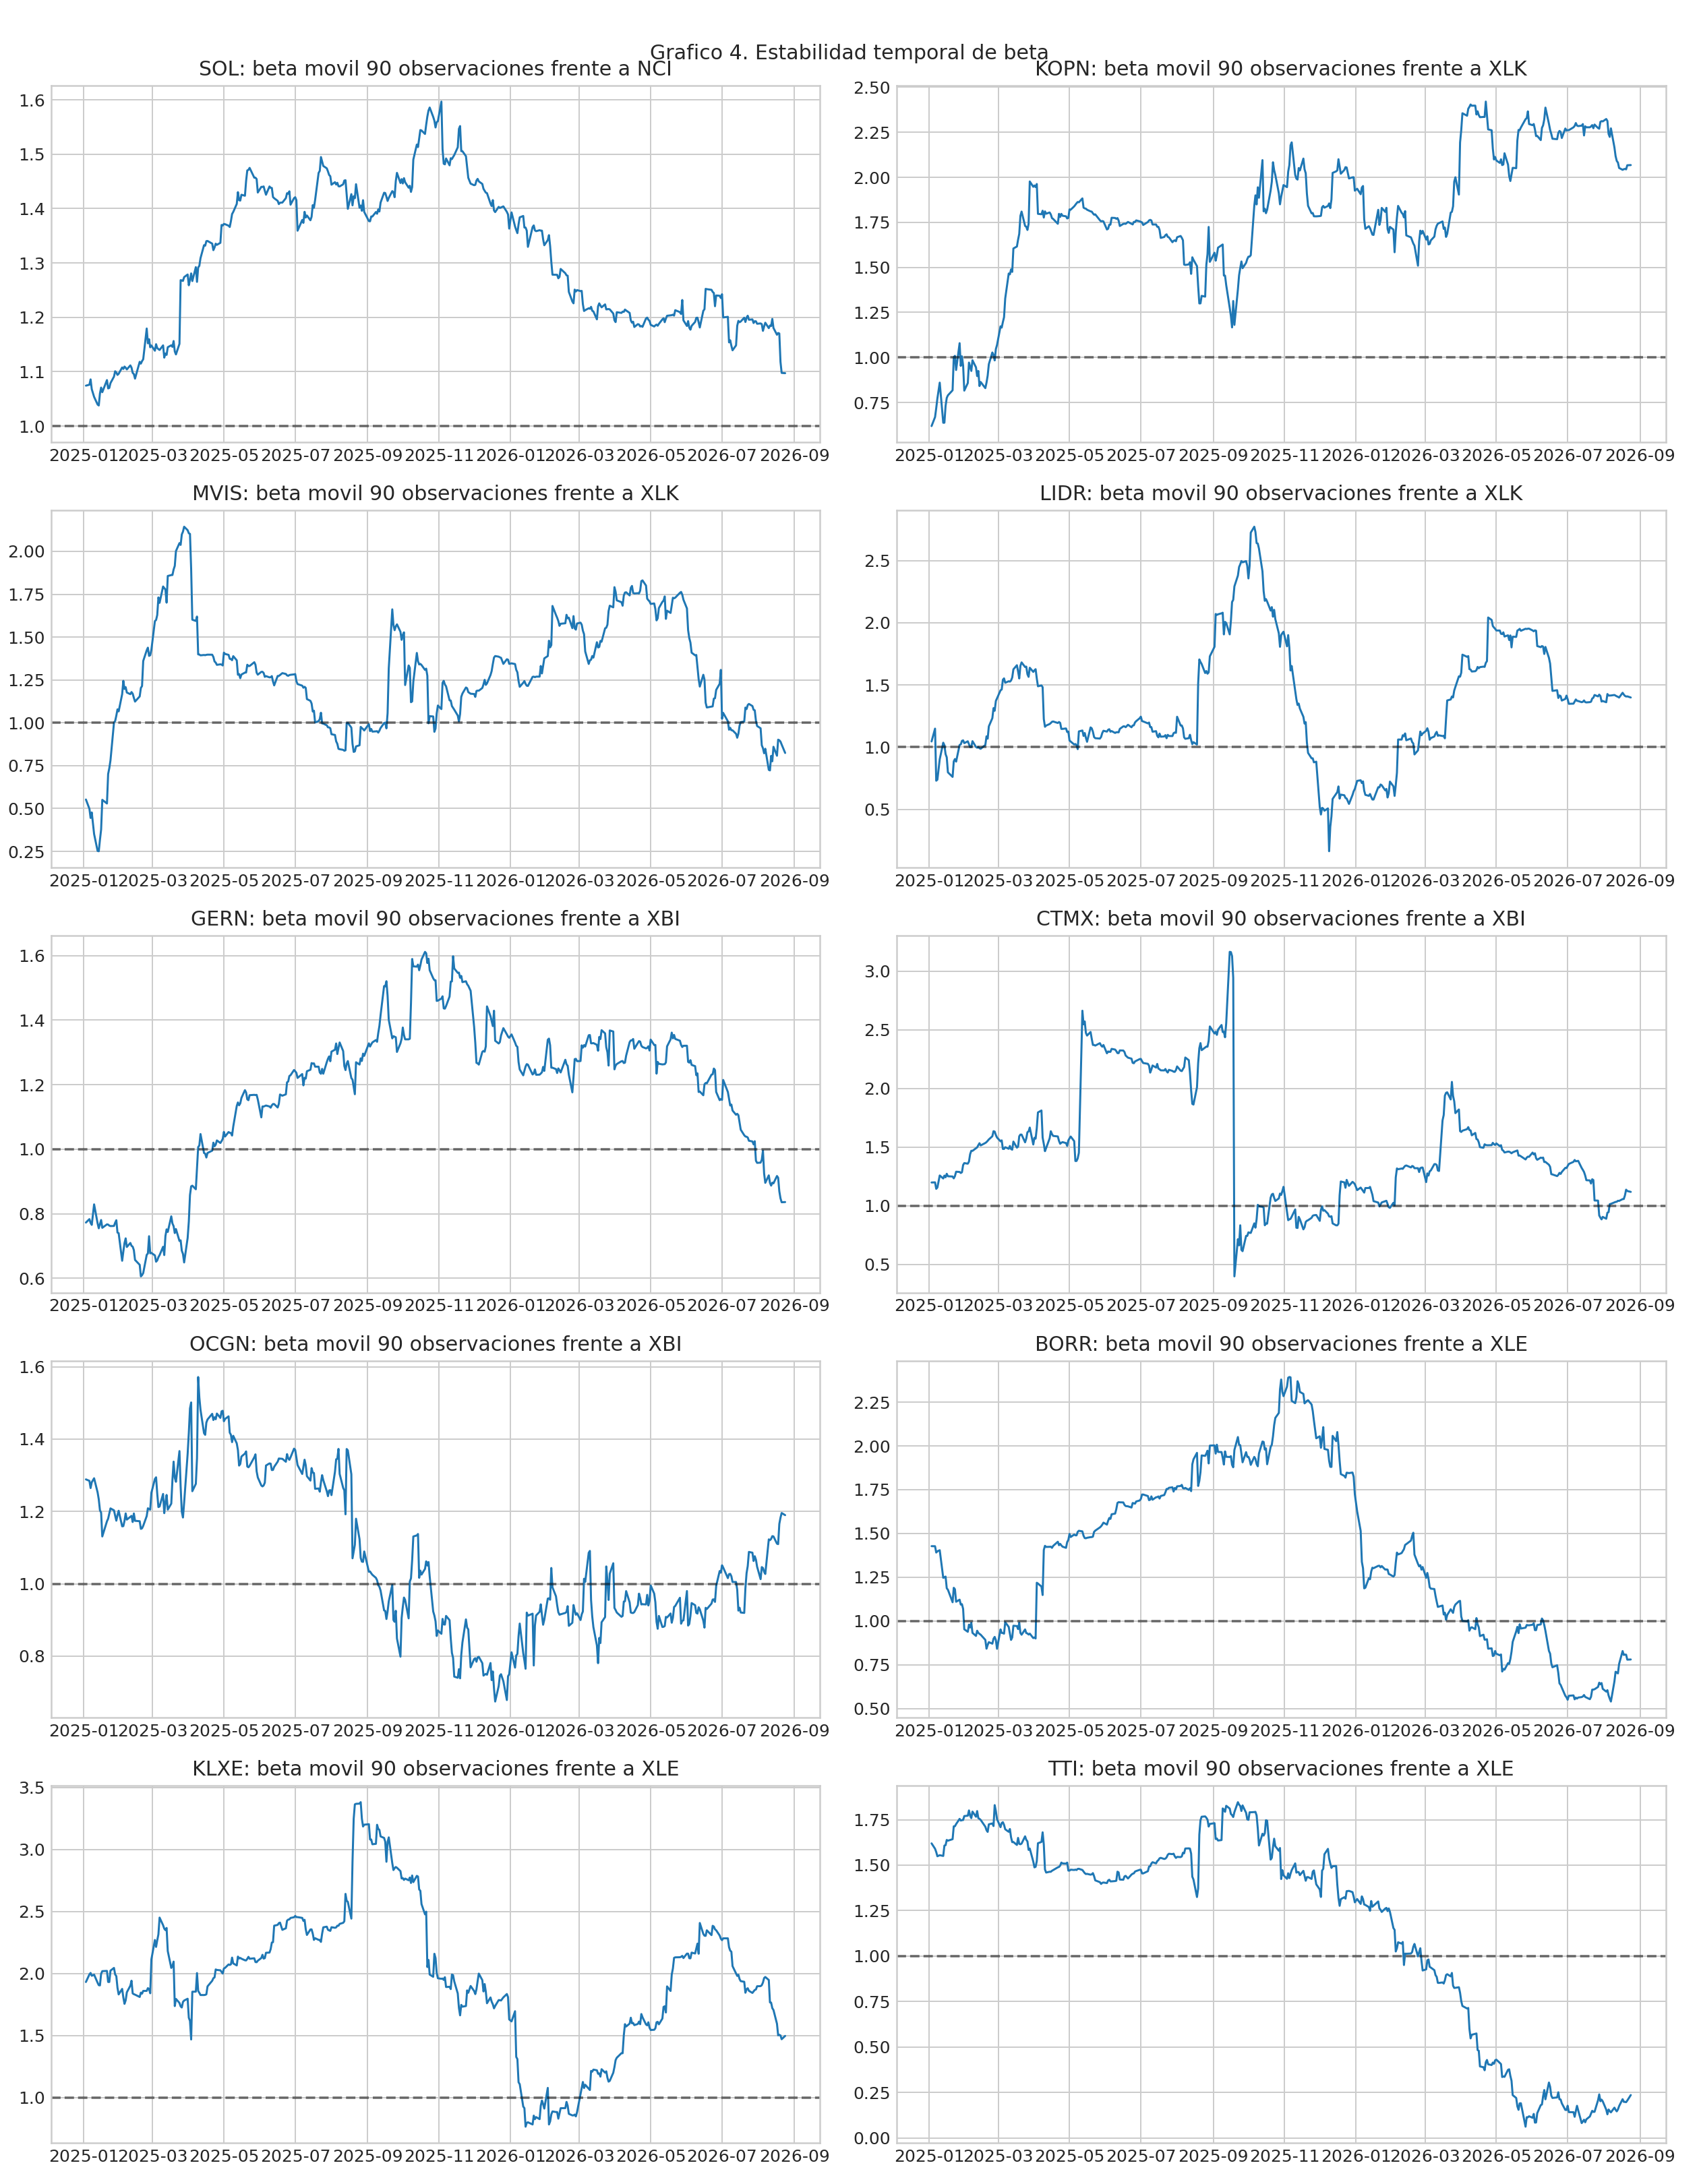

=== Visualizacion: grafico_5_mapa_riesgo_retorno.png ===


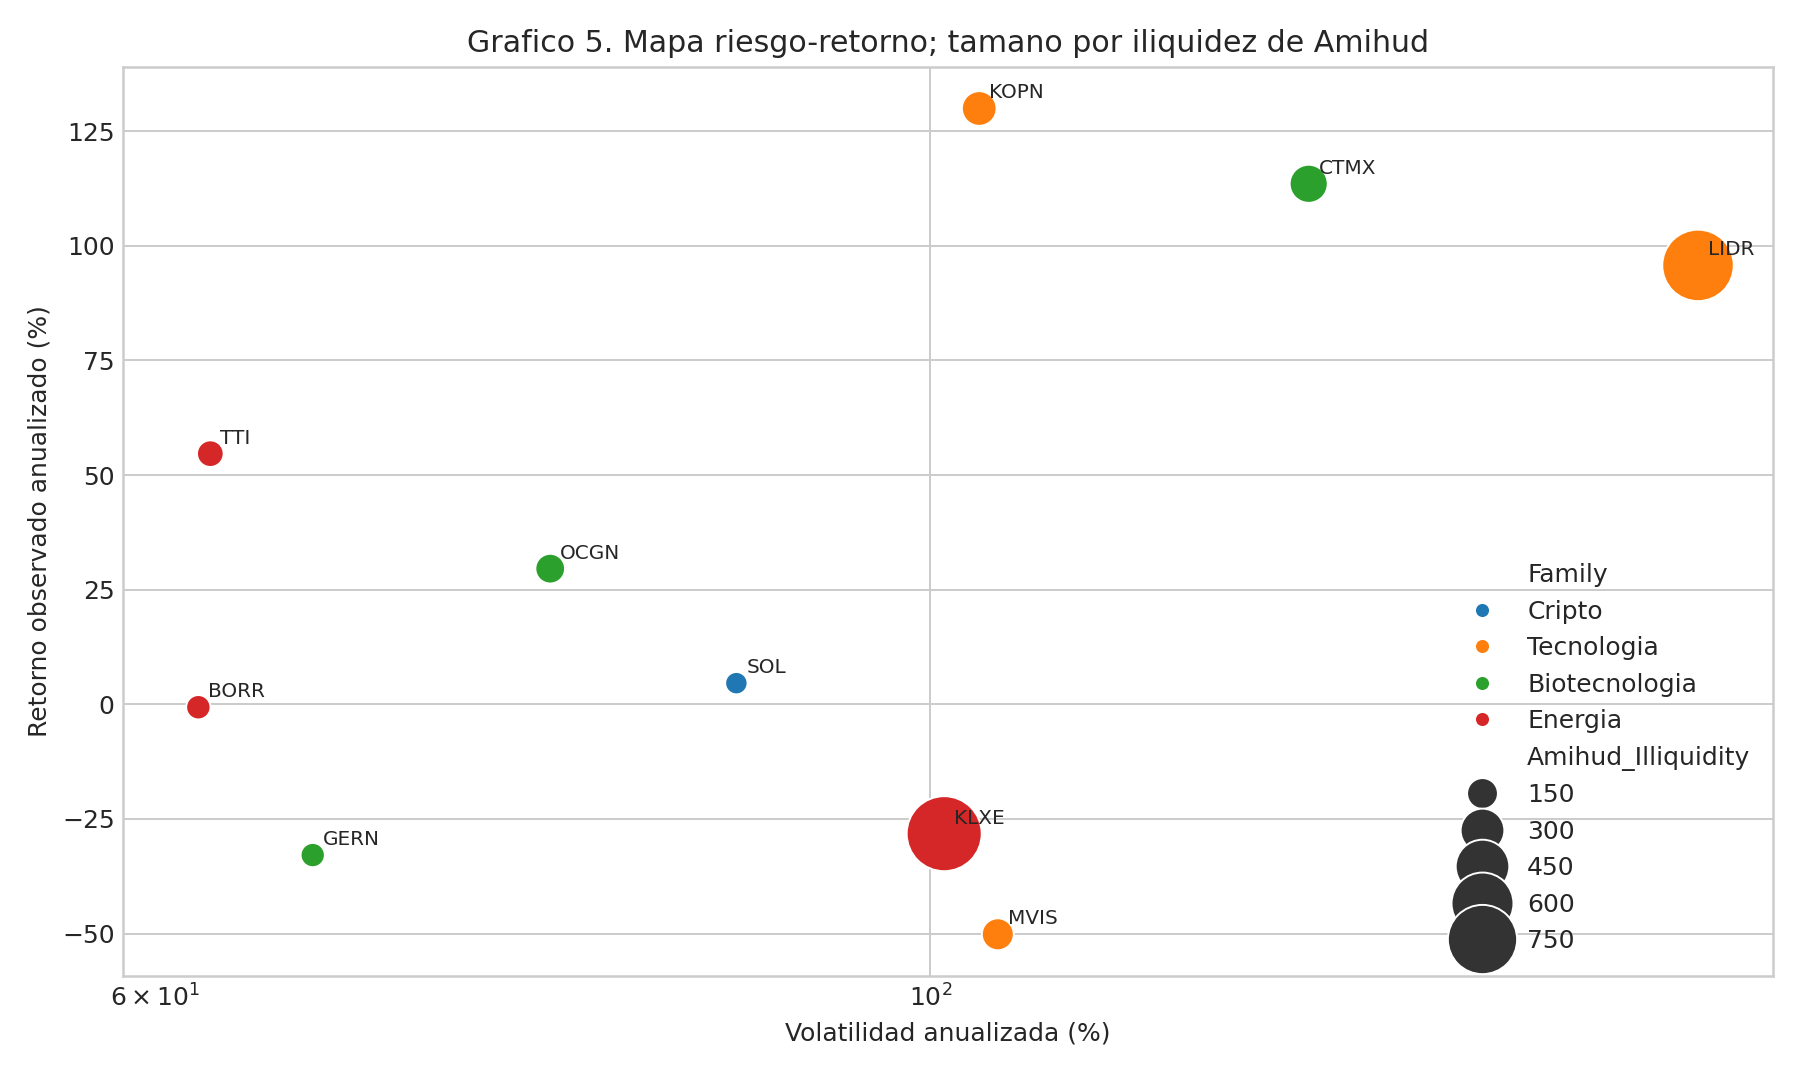

=== Visualizacion: grafico_6_drawdown_acumulado_todos.png ===


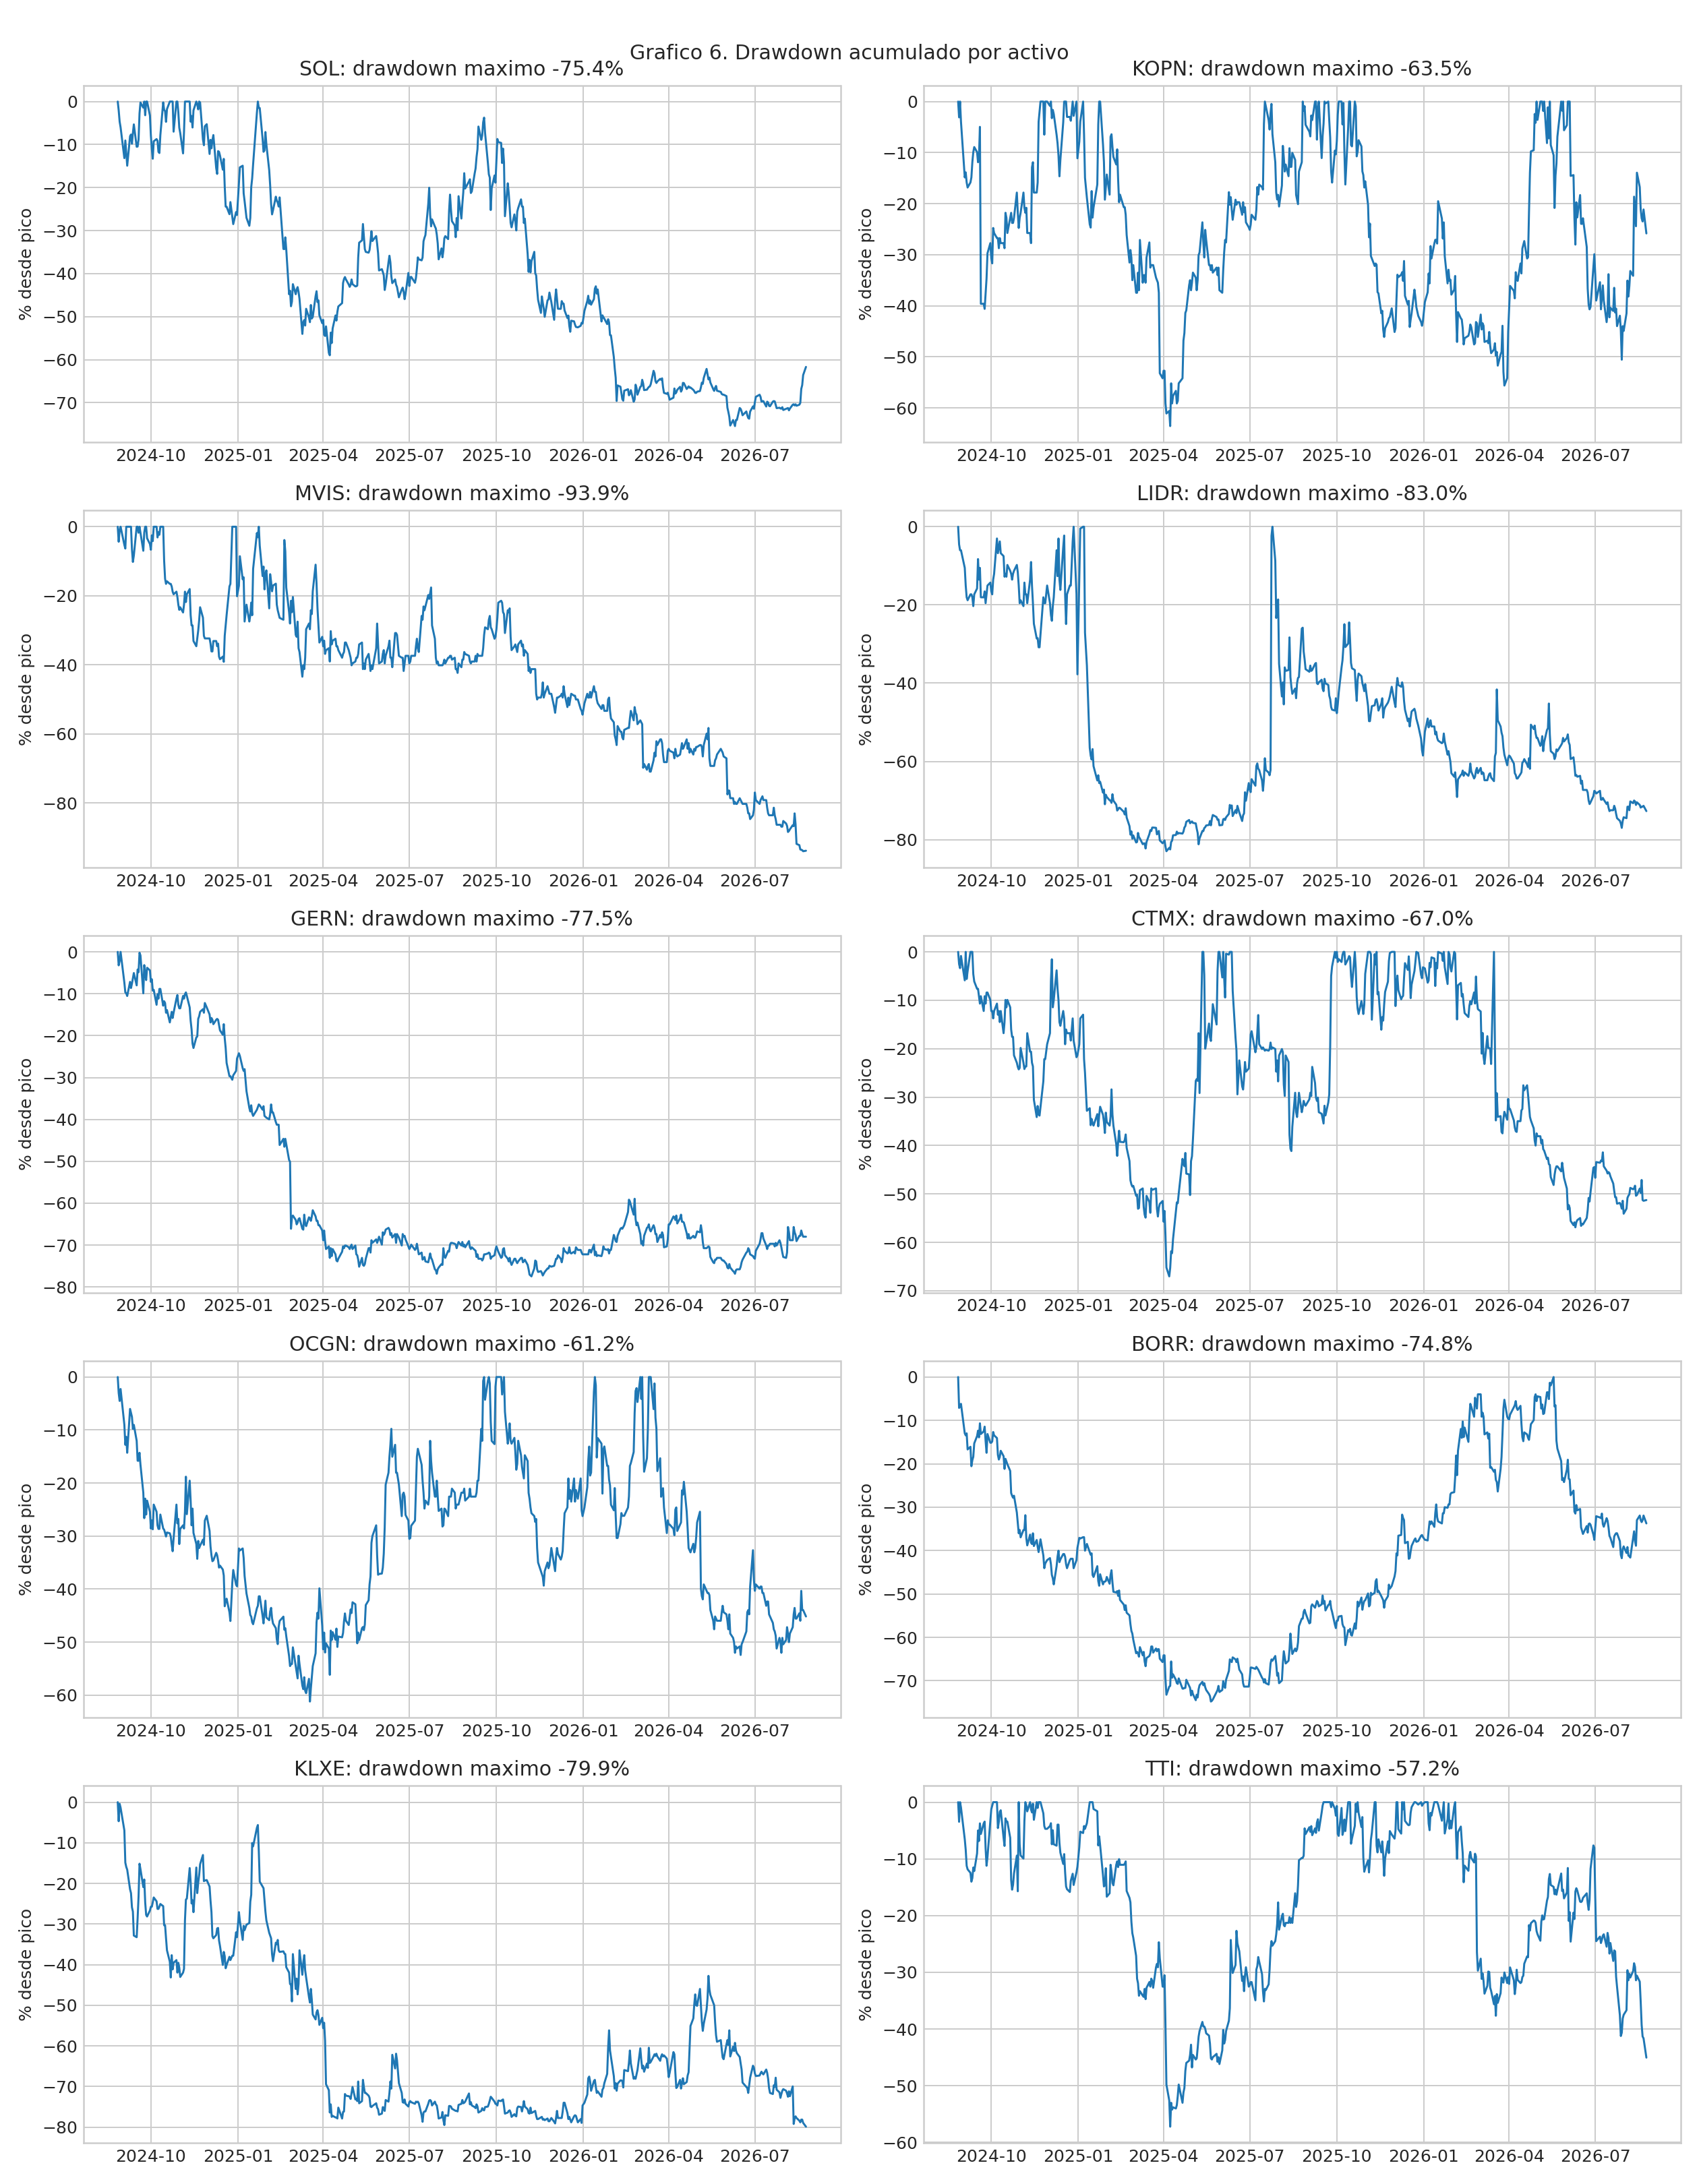

=== Visualizacion: grafico_7_matriz_percentiles.png ===


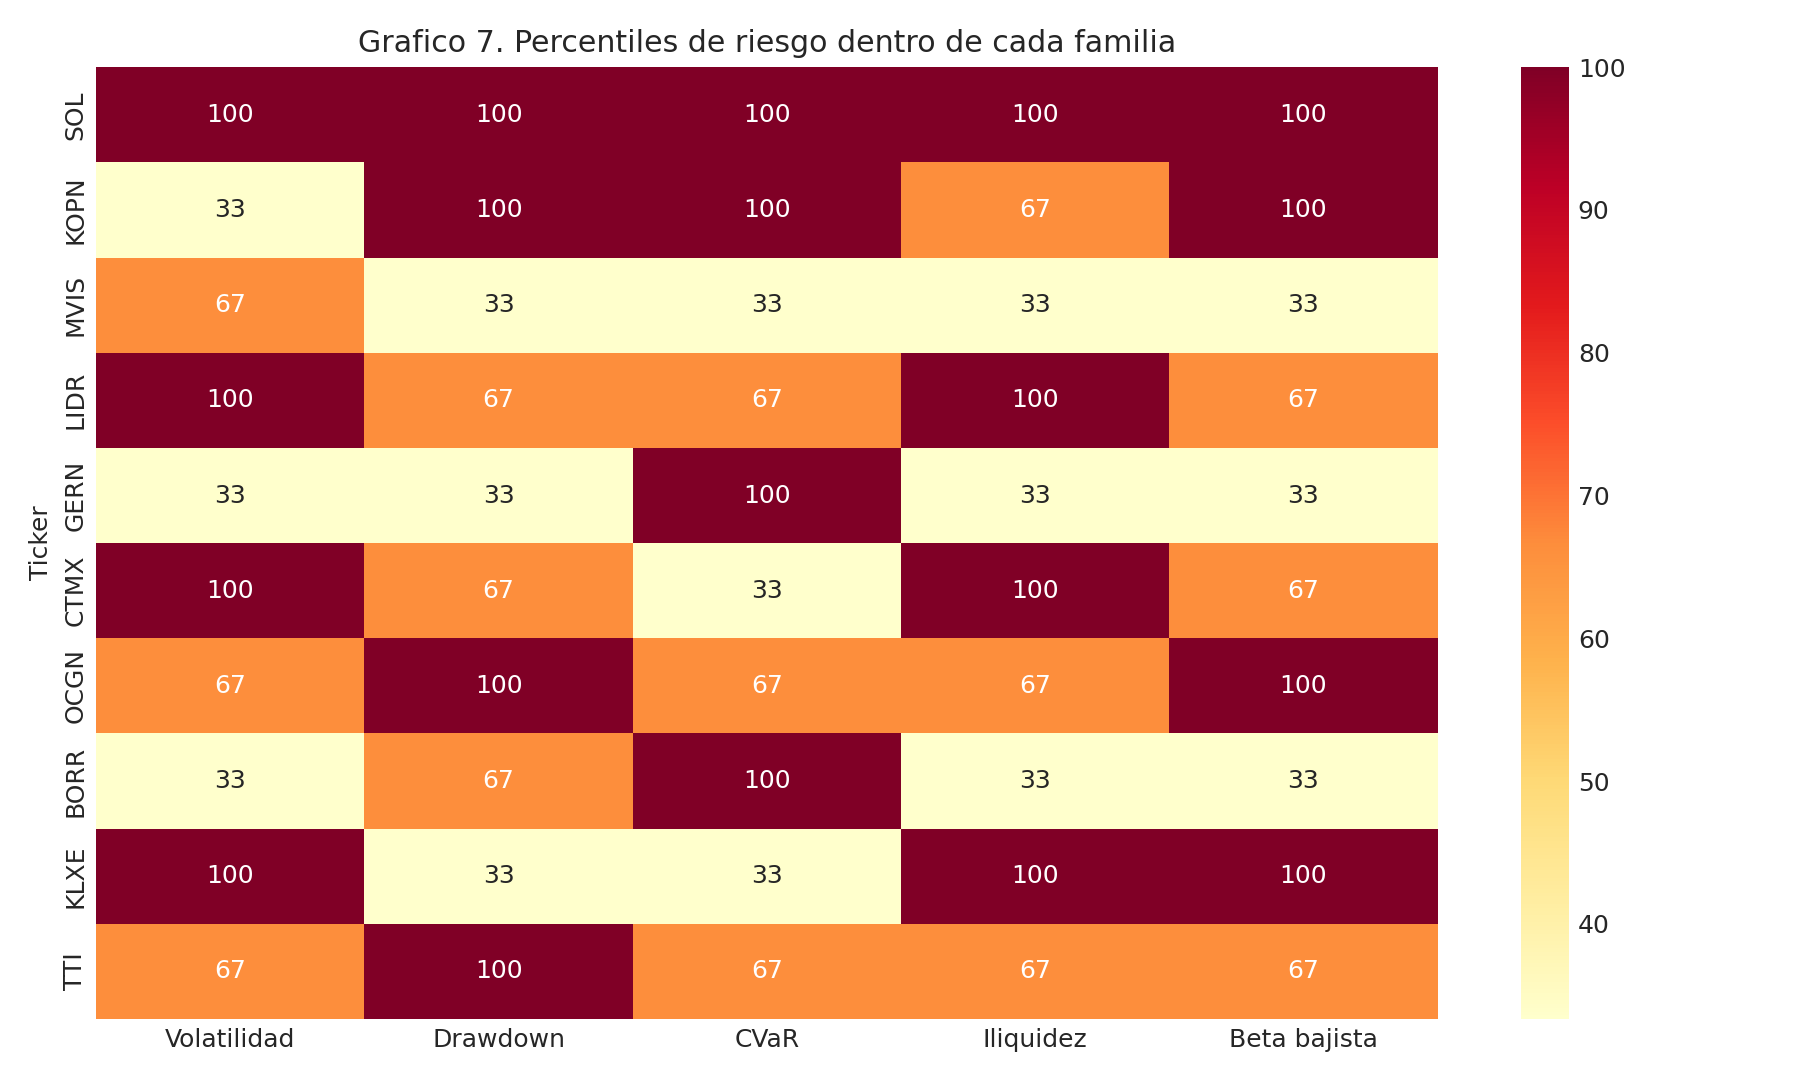

In [6]:
from IPython.display import Image, display
for filename in [
    'grafico_1_precios_normalizados.png',
    'grafico_2_recta_capm_todos.png',
    'grafico_3_forest_plot_betas.png',
    'grafico_4_beta_movil_todos.png',
    'grafico_5_mapa_riesgo_retorno.png',
    'grafico_6_drawdown_acumulado_todos.png',
    'grafico_7_matriz_percentiles.png',
]:
    imgPath = graficos_dir / filename
    if imgPath.exists():
        print(f'=== Visualizacion: {filename} ===')
        display(Image(filename=str(imgPath)))

## Dictamen final y recomendación para Doña Victoria

El objetivo de alcanzar un retorno del 25% anual sin asumir caídas es técnicamente irrealizable en el mercado de capitales: la evidencia econométrica de drawdowns severos (-75% a -93%), CVaR e iliquidez demuestra que todo retorno elevado exige pagar una factura de riesgo sustancial.

1. **Mandato de Conservación (Preservación de Patrimonio):** Rechazo total de los 10 expedientes. Su elevada volatilidad e iliquidez exponen el capital a riesgo de ruina. Se recomienda la asignación del 100% en tasa libre de riesgo (Treasury Bills a 3 meses, DGS3MO).

2. **Mandato de Crecimiento (Acumulación Sistemática):** Se debe evitar la selección individual de acciones de bajo precio (penny stocks) debido a su fragilidad operativa y spread de salida. La asignación debe realizarse de forma diversificada a través de los ETF de referencia sectorial (XLK, XLE, XBI).

3. **Mandato de Especulación con Riesgo Controlado (Asignación Táctica Marginal):** Para aquellos activos que generaron alfa positivo (KOPN, LIDR, CTMX, TTI) o para la exposición a criptoactivos (SOL), se permite una posición pequeña y acotada entre el 1% y el 2% del portafolio total, condicionada obligatoriamente a un presupuesto de pérdida máxima estricto (stop-loss predefinido del 15%), garantizando que ningún choque adverso comprometa el patrimonio familiar.

La beta debe ser interpretada dentro de su benchmark propio: SOL frente al NCI, tecnología frente a XLK, biotecnología frente a XBI y energía frente a XLE. Una beta baja no debe aceptarse como defensiva si viene acompañada de días con retorno cero, bajo volumen monetario o distorsiones de negociación no sincrónica.